
# Proyecto final: Análisis de la abundancia del lobo marino de Galápagos mediante R

**Curso:** OceanHackWeek 2026 – Semana Pre-Hackatón

**Especie:** *Zalophus wollebaeki*

**Área de estudio:** Islote Caamaño, Galápagos, Ecuador

**Periodo:** 2003–2023

## Introducción

Para este proyecto se utilizaron datos de censos del lobo marino de Galápagos (*Zalophus wollebaeki*), publicados por Childs et al. (2026) en el repositorio científico Dryad.

El objetivo es explorar cómo ha variado la abundancia observada de estos organismos a lo largo del tiempo, utilizando herramientas básicas de R para organizar los datos, calcular promedios y elaborar gráficos.

El trabajo se desarrolla utilizando un notebook en JupyterLab y un archivo independiente de funciones creado en RStudio, con el propósito de aprender a organizar y reutilizar código.


In [1]:
# Cargar las funciones creadas en RStudio
source("R/funciones_lobos_marinos.R")

# Comprobar que están disponibles
exists("Media")
exists("graficar_abundancia")

[1] TRUE

[1] TRUE

In [2]:
# Cargar los datos de censos
lobos <- read.csv("Datos/census_avg.csv")

# Mostrar las primeras seis filas
head(lobos)

# Conocer las dimensiones
dim(lobos)

,SeasonOfRound,Males_avg,Females_avg,Females_max,Adults_avg,All_Adults_avg,Juveniles_avg,Pups_avg,Total_avg,Total_avg_wo_pups,⋯,Males_avg_ex,Females_avg_ex,Adults_avg_ex,All_Adults_avg_ex,Juveniles_avg_ex,Pups_avg_ex,Total_avg_ex,n_counts_ex,Total_avg_wo_pups_ex,Total_avg_wo_fem_pups_ex
,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,1,21,75,93,5,101,88,48,237,189,⋯,21,75,5,101,88,48,237,25,189,114
2,2,32,86,98,4,122,92,86,300,214,⋯,32,86,4,122,92,86,300,12,214,129
3,3,25,64,86,6,95,6,41,142,101,⋯,25,64,6,95,6,41,142,15,101,37
4,4,35,67,93,38,140,91,98,329,231,⋯,34,89,8,131,107,97,335,23,238,149
5,4,35,67,93,38,140,91,98,329,231,⋯,36,61,46,142,87,98,328,8,230,168
6,5,31,81,116,11,122,11,46,179,132,⋯,30,82,8,120,8,41,169,37,129,47


[1] 37 25

In [3]:

# Seleccionar una observacion por temporada reproductiva
anuales <- lobos[!duplicated(lobos$SeasonOfRound), ]

# Seleccionar las variables de interes
anuales <- anuales[, c(
  "SeasonOfRound_YearStart",
  "All_Adults_avg",
  "Females_avg",
  "Males_avg",
  "Adults_avg",
  "Juveniles_avg",
  "Pups_avg"
)]

# Ordenar los datos por año
anuales <- anuales[
  order(anuales$SeasonOfRound_YearStart),
]

# Comprobar dimensiones y visualizar registros
dim(anuales)
head(anuales)


[1] 21  7

,SeasonOfRound_YearStart,All_Adults_avg,Females_avg,Males_avg,Adults_avg,Juveniles_avg,Pups_avg
,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,2003,101,75,21,5,88,48
2,2004,122,86,32,4,92,86
3,2005,95,64,25,6,6,41
4,2006,140,67,35,38,91,98
6,2007,122,81,31,11,11,46
8,2008,85,59,18,8,8,65



## Funciones propias utilizadas

Para realizar el análisis se desarrollaron dos funciones propias en R, almacenadas en el archivo `R/funciones_lobos_marinos.R`.

**Media():** permite calcular la media aritmética de una variable numérica, excluyendo los valores faltantes.

**graficar_abundancia():** permite elaborar gráficos de variación temporal de la abundancia observada, seleccionando la variable de interés, el título y el color.

Estas funciones permiten reutilizar instrucciones y evitar repetir código.


In [4]:

# Calcular promedios mediante la funcion propia Media()

promedio_hembras <- Media(anuales$Females_avg)
promedio_machos <- Media(anuales$Males_avg)
promedio_adultos_no_identificados <- Media(anuales$Adults_avg)
promedio_adultos <- Media(anuales$All_Adults_avg)
promedio_juveniles <- Media(anuales$Juveniles_avg)
promedio_crias <- Media(anuales$Pups_avg)

# Crear tabla resumen
resumen <- data.frame(
  Categoria = c(
    "Hembras adultas",
    "Machos adultos",
    "Adultos sin sexo identificado",
    "Todos los adultos",
    "Juveniles",
    "Crías"
  ),
  Promedio = round(c(
    promedio_hembras,
    promedio_machos,
    promedio_adultos_no_identificados,
    promedio_adultos,
    promedio_juveniles,
    promedio_crias
  ), 2)
)

resumen


Categoria,Promedio
<chr>,<dbl>
Hembras adultas,48.71
Machos adultos,17.95
Adultos sin sexo identificado,5.81
Todos los adultos,72.24
Juveniles,16.48
Crías,39.71



## Variación temporal de la abundancia

Se examinó la variación temporal de la abundancia media observada de diferentes categorías de lobos marinos durante las temporadas reproductivas comprendidas entre 2003 y 2023.

Los gráficos fueron elaborados mediante la función propia `graficar_abundancia()`.


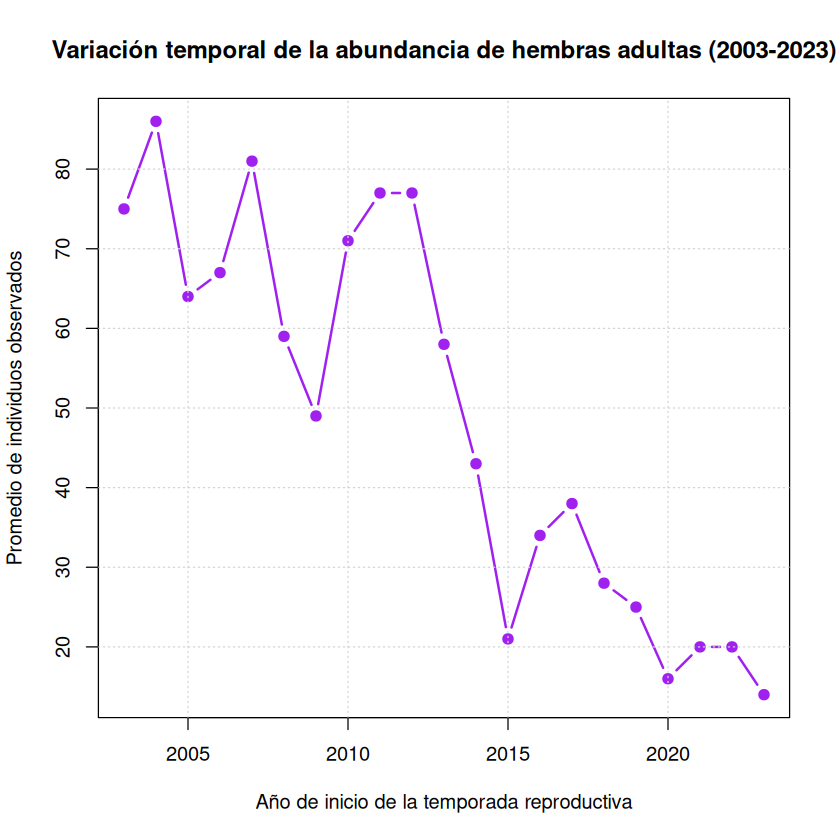

In [5]:

graficar_abundancia(
  anuales,
  "Females_avg",
  "Variación temporal de la abundancia de hembras adultas (2003-2023)",
  "purple"
)


El gráfico muestra las fluctuaciones en la abundancia media observada de hembras adultas de *Zalophus wollebaeki* durante las temporadas reproductivas de 2003 a 2023 en el islote Caamaño. Se observan diferencias entre temporadas y una disminución general de los registros hacia el final del período estudiado.

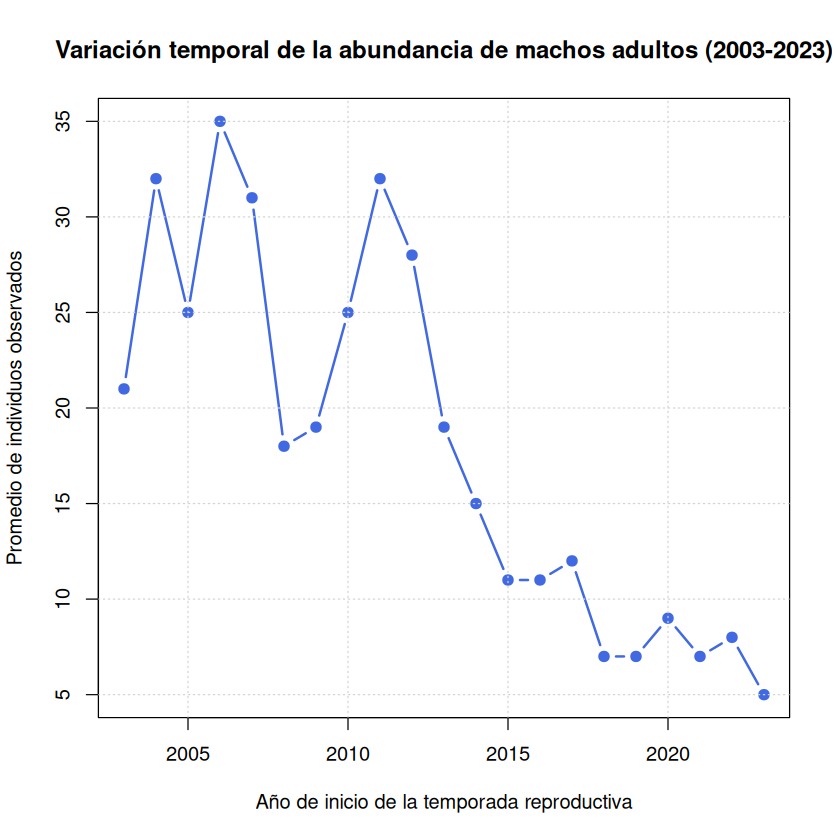

In [6]:

graficar_abundancia(
  anuales,
  "Males_avg",
  "Variación temporal de la abundancia de machos adultos (2003-2023)",
  "royalblue"
)


Se presenta la variación temporal de la abundancia media de machos adultos registrados durante los censos. El gráfico permite identificar cambios entre temporadas reproductivas y observar el comportamiento de esta categoría a lo largo de los 21 años de estudio.

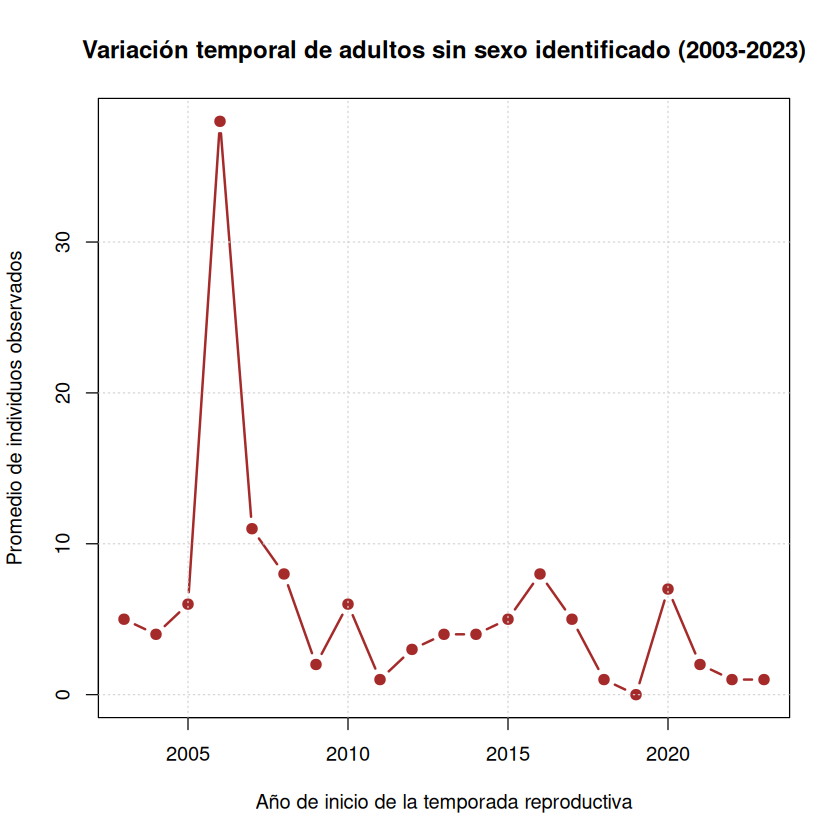

In [7]:

graficar_abundancia(
  anuales,
  "Adults_avg",
  "Variación temporal de adultos sin sexo identificado (2003-2023)",
  "brown"
)


El gráfico representa las fluctuaciones en la abundancia media de adultos cuyo sexo no pudo identificarse durante los censos. Esta categoría complementa los registros de machos y hembras adultos y permite reconocer la presencia de individuos que no pudieron clasificarse por sexo.

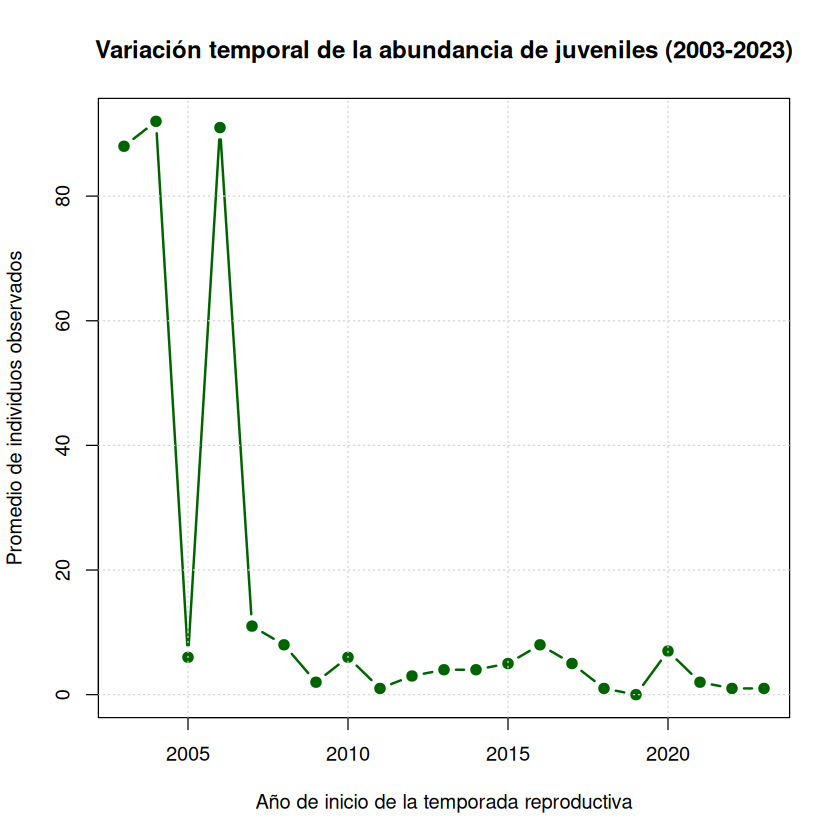

In [8]:

graficar_abundancia(
  anuales,
  "Juveniles_avg",
  "Variación temporal de la abundancia de juveniles (2003-2023)",
  "darkgreen"
)


Se observa una marcada variabilidad en los registros de juveniles, con valores elevados en algunas temporadas iniciales y abundancias considerablemente menores en gran parte de los años posteriores. Este comportamiento evidencia cambios temporales en la abundancia observada de esta categoría de edad.

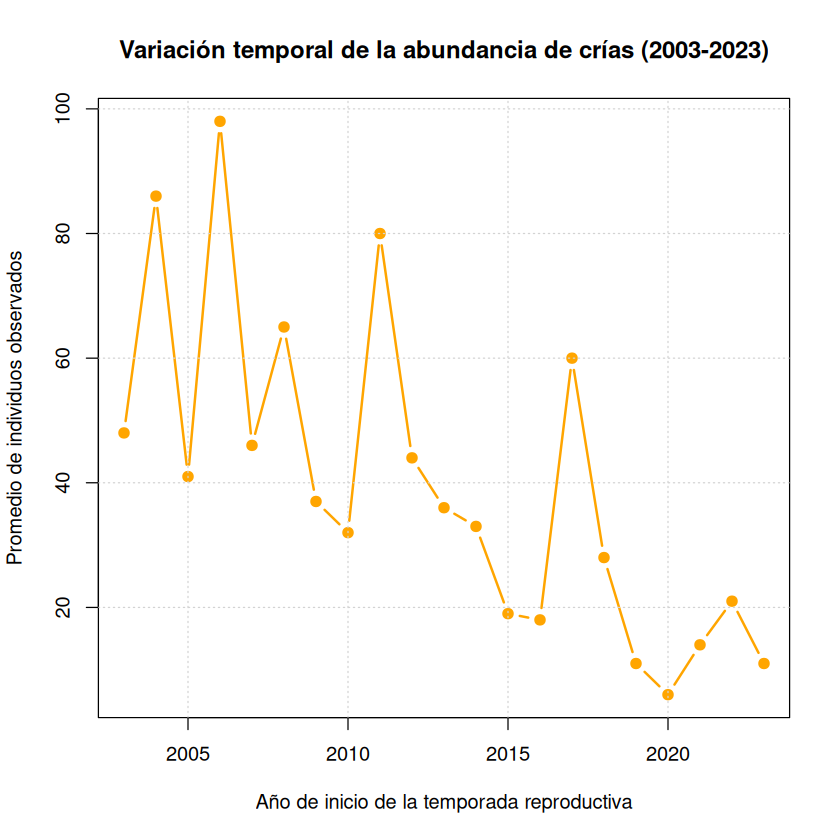

In [9]:

graficar_abundancia(
  anuales,
  "Pups_avg",
  "Variación temporal de la abundancia de crías (2003-2023)",
  "orange"
)


El gráfico muestra fluctuaciones importantes en la abundancia media de crías entre temporadas reproductivas. Se identifican años con registros relativamente elevados y otros con valores menores, lo que permite describir la variabilidad temporal de esta categoría, sin asumir que representa directamente el número de nacimientos.

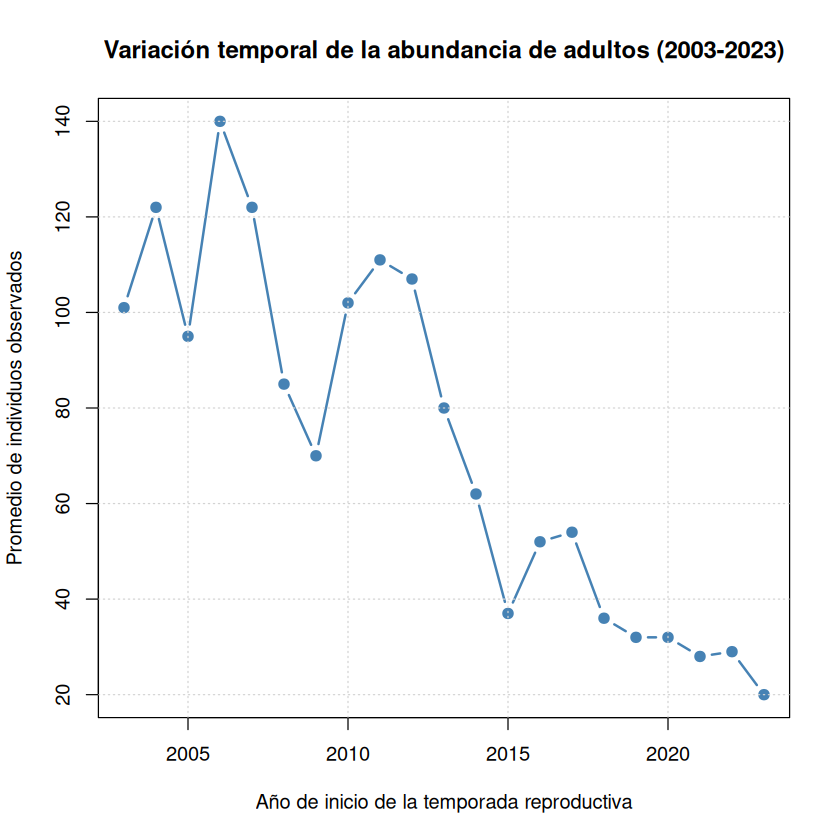

In [10]:

graficar_abundancia(
  anuales,
  "All_Adults_avg",
  "Variación temporal de la abundancia de adultos (2003-2023)",
  "steelblue"
)


Se representa la abundancia media de todos los individuos adultos, incluyendo machos, hembras y adultos sin sexo identificado. Los resultados muestran fluctuaciones entre temporadas y una tendencia visual general decreciente, con valores de abundancia menores hacia el final del período de estudio.


## Comparación de abundancia promedio por categoría de edad

Se compararon los promedios de abundancia de adultos, juveniles y crías durante el período 2003–2023.

Este análisis permite identificar las diferencias entre las categorías de edad considerando el conjunto de temporadas reproductivas.


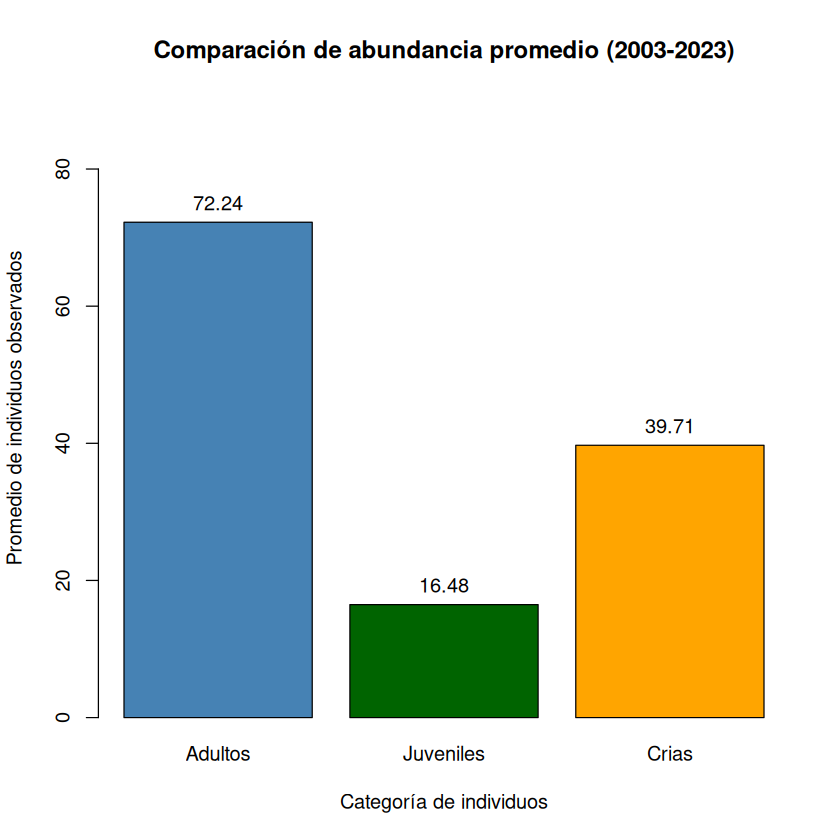

In [11]:

promedios <- c(
  Adultos = promedio_adultos,
  Juveniles = promedio_juveniles,
  Crias = promedio_crias
)

barras <- barplot(
  promedios,
  col = c("steelblue", "darkgreen", "orange"),
  main = "Comparación de abundancia promedio (2003-2023)",
  xlab = "Categoría de individuos",
  ylab = "Promedio de individuos observados",
  ylim = c(0, max(promedios) * 1.25)
)

text(
  x = barras,
  y = promedios,
  labels = round(promedios, 2),
  pos = 3
)



Los adultos presentaron la mayor abundancia promedio (72,24 individuos), seguidos de las crías (39,71) y los juveniles (16,48).

Estos valores corresponden a promedios de individuos observados durante los censos y no representan estimaciones de la población total del archipiélago.


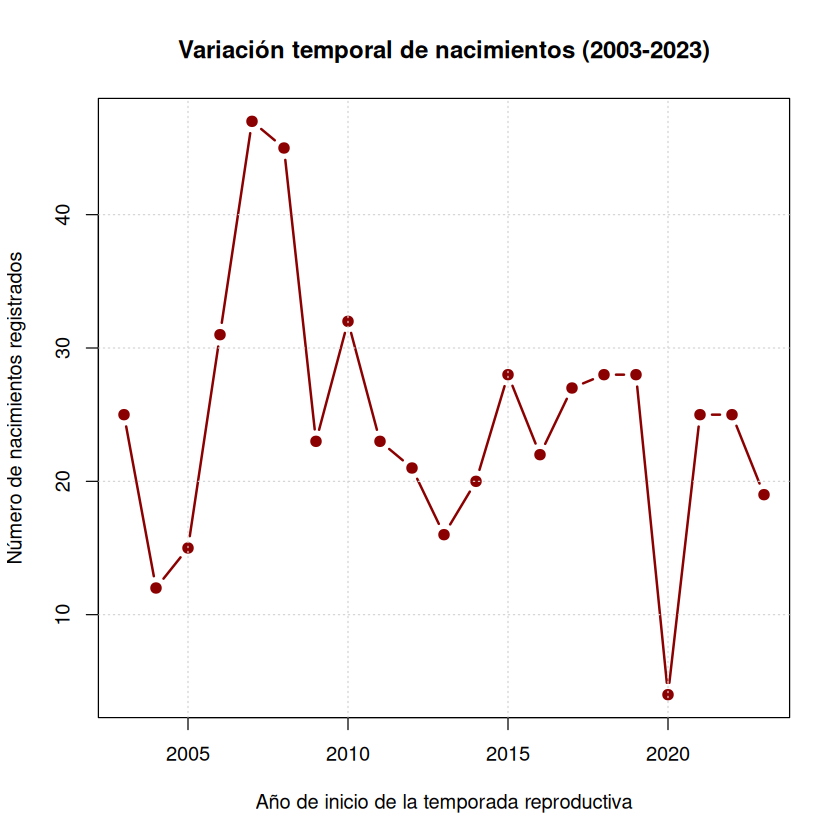

In [12]:

# Seleccionar nacimientos por temporada reproductiva
nacimientos <- lobos[
  !duplicated(lobos$SeasonOfRound),
  c("SeasonOfRound_YearStart", "n_counts")
]

nacimientos <- nacimientos[
  order(nacimientos$SeasonOfRound_YearStart),
]

# Crear grafico
plot(
  nacimientos$SeasonOfRound_YearStart,
  nacimientos$n_counts,
  type = "b",
  col = "darkred",
  pch = 19,
  lwd = 2,
  xlab = "Año de inicio de la temporada reproductiva",
  ylab = "Número de nacimientos registrados",
  main = "Variación temporal de nacimientos (2003-2023)"
)

grid()



El gráfico muestra las fluctuaciones en el número de nacimientos registrados durante las temporadas reproductivas estudiadas.

A diferencia de los gráficos de abundancia, esta variable corresponde a un conteo de nacimientos y no al promedio de crías observadas durante los censos.


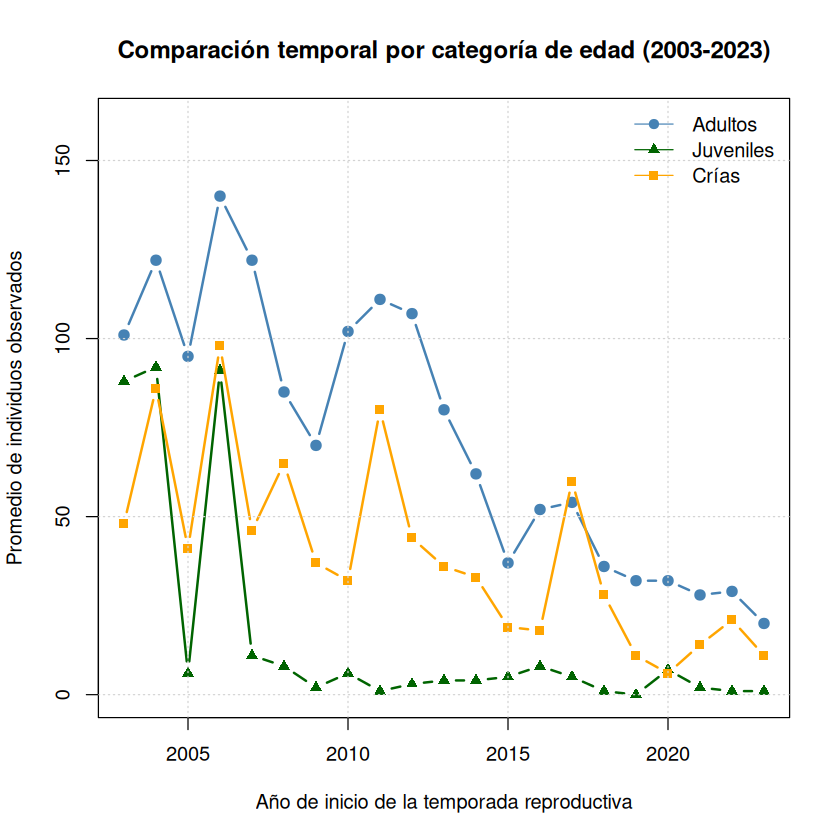

In [13]:

# Limite del eje Y
limite_y <- max(
  anuales$All_Adults_avg,
  anuales$Juveniles_avg,
  anuales$Pups_avg,
  na.rm = TRUE
) * 1.15

# Adultos
plot(
  anuales$SeasonOfRound_YearStart,
  anuales$All_Adults_avg,
  type = "b",
  col = "steelblue",
  pch = 19,
  lwd = 2,
  ylim = c(0, limite_y),
  xlab = "Año de inicio de la temporada reproductiva",
  ylab = "Promedio de individuos observados",
  main = "Comparación temporal por categoría de edad (2003-2023)"
)

# Juveniles
lines(
  anuales$SeasonOfRound_YearStart,
  anuales$Juveniles_avg,
  type = "b",
  col = "darkgreen",
  pch = 17,
  lwd = 2
)

# Crias
lines(
  anuales$SeasonOfRound_YearStart,
  anuales$Pups_avg,
  type = "b",
  col = "orange",
  pch = 15,
  lwd = 2
)

legend(
  "topright",
  legend = c("Adultos", "Juveniles", "Crías"),
  col = c("steelblue", "darkgreen", "orange"),
  lty = 1,
  pch = c(19, 17, 15),
  bty = "n"
)

grid()



La comparación temporal muestra fluctuaciones en la abundancia media observada de adultos, juveniles y crías.

En general, los adultos presentaron los mayores valores, mientras que las crías superaron a los juveniles en numerosas temporadas. Hacia el final del período se observaron valores menores que en varios de los primeros años.

Este análisis descriptivo no permite estimar directamente tasas de supervivencia o mortalidad.



	Spearman's rank correlation rho

data:  datos_reproduccion$Females_avg and datos_reproduccion$n_counts
S = 1363.9, p-value = 0.6216
alternative hypothesis: true rho is not equal to 0
sample estimates:
      rho 
0.1143698 


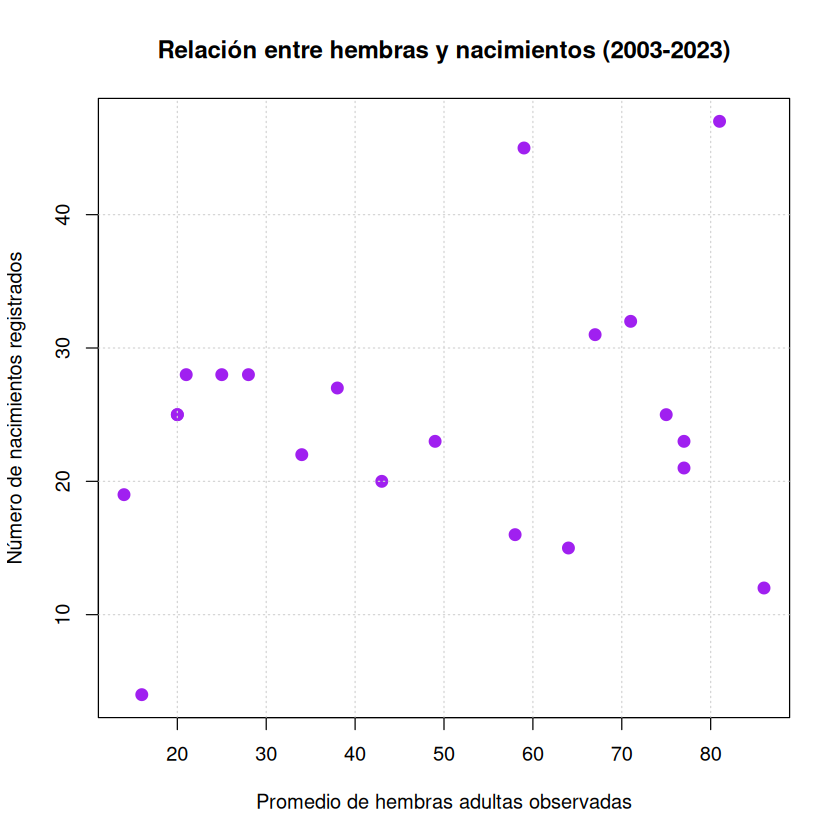

In [14]:

# Seleccionar datos de hembras y nacimientos
datos_reproduccion <- lobos[
  !duplicated(lobos$SeasonOfRound),
  c(
    "SeasonOfRound_YearStart",
    "Females_avg",
    "n_counts"
  )
]

datos_reproduccion <- datos_reproduccion[
  order(datos_reproduccion$SeasonOfRound_YearStart),
]

datos_reproduccion <- na.omit(datos_reproduccion)

# Grafico de dispersion
plot(
  datos_reproduccion$Females_avg,
  datos_reproduccion$n_counts,
  pch = 19,
  col = "purple",
  cex = 1.3,
  xlab = "Promedio de hembras adultas observadas",
  ylab = "Número de nacimientos registrados",
  main = "Relación entre hembras y nacimientos (2003-2023)"
)

grid()

# Correlacion de Spearman
resultado_spearman <- cor.test(
  datos_reproduccion$Females_avg,
  datos_reproduccion$n_counts,
  method = "spearman",
  exact = FALSE
)

resultado_spearman



El análisis exploratorio mediante correlación de Spearman mostró una asociación monotónica positiva muy débil entre la abundancia media de hembras adultas y los nacimientos registrados (rho = 0,1144; p = 0,6216).

No se encontró evidencia estadística suficiente de una asociación monotónica entre las variables. Este resultado no demuestra la ausencia de una relación biológica, y debe interpretarse considerando las características de los censos y la naturaleza temporal de los datos.



## Conclusiones

1. Se analizaron registros de censos del lobo marino de Galápagos (*Zalophus wollebaeki*) correspondientes a 21 temporadas reproductivas entre 2003 y 2023 en el islote Caamaño.

2. Los adultos presentaron el mayor promedio de abundancia observada (72,24 individuos), seguidos de las crías (39,71) y los juveniles (16,48).

3. Los gráficos temporales evidenciaron fluctuaciones de abundancia entre temporadas reproductivas, con registros generalmente menores hacia el final del período de estudio.

4. El número de nacimientos registrados presentó variaciones entre temporadas. La correlación exploratoria de Spearman no identificó una asociación monotónica estadísticamente significativa entre la abundancia media de hembras adultas y el número de nacimientos (rho = 0,1144; p = 0,6216).

5. El uso de funciones propias en R permitió calcular promedios y generar visualizaciones de manera organizada y reutilizable. Este ejercicio contribuyó al aprendizaje del procesamiento, análisis exploratorio y representación gráfica de datos biológicos.

**Limitaciones:** Los resultados corresponden a registros de censos y promedios de observación. No deben interpretarse como estimaciones directas de supervivencia, mortalidad o tamaño poblacional de todo el archipiélago.

## Fuente de datos

Childs et al. (2026). *Pupping and yearling survival in Galápagos Sea Lions: impact of maternal investment, environmental fluctuations and population decline*. Dryad.

https://doi.org/10.5061/dryad.zs7h44jr0
